In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
from torch.utils.data import Dataset, DataLoader
import numpy as np
import math
import random
import matplotlib.pyplot as plt
from tqdm import tqdm


device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
class Transformer(nn.Module):
    def __init__(self, n_Layers, n_Embd=16, max_seq_length=20, n_Classes=1):
        super(Transformer, self).__init__()
        
        self.src_embedding = nn.Linear(in_features=n_Classes, out_features=n_Embd)
        self.tgt_embedding = nn.Linear(in_features=n_Classes, out_features=n_Embd)
        
        self.positional_encoding = nn.Parameter(self.create_positional_encoding(max_seq_length, n_Embd), requires_grad=False)
        
        encoder_layer = nn.TransformerEncoderLayer(n_Embd, nhead=8, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, n_Layers)
        
        decoder_layer = nn.TransformerDecoderLayer(n_Embd, nhead=8, activation="gelu", batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(decoder_layer, n_Layers)
        
        self.lin = nn.Linear(n_Embd, n_Classes)
        
        self.register_buffer("tril", torch.tril(torch.ones(max_seq_length, max_seq_length)))

    @staticmethod
    def create_positional_encoding(max_seq_length, n_Embd):
        pe = torch.zeros(max_seq_length, n_Embd)
        position = torch.arange(0, max_seq_length, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, n_Embd, 2).float() * (-math.log(10000.0) / n_Embd))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)

    def forward(self, src, tgt, past_key_values=None):

        if past_key_values is None:
            embedded_src = self.src_embedding(src) + self.positional_encoding[:, :src.size(1), :]
            memory = self.encoder(embedded_src)
            past_key_values = [[memory], [None] * len(self.decoder.layers)]
            past_length_tgt = 0
        else:
            memory = past_key_values[0][0]
            past_length_tgt = past_key_values[1][0].size(1)
            

        embedded_tgt = self.tgt_embedding(tgt) + self.positional_encoding[:, past_length_tgt:past_length_tgt+tgt.size(1), :]

        for i, layer in enumerate(self.decoder.layers):
            if past_key_values[1][i] is not None:
                layer_input = torch.cat([past_key_values[1][i], embedded_tgt], dim=1)
            else:
                layer_input = embedded_tgt

            layer_output = layer(layer_input, memory, tgt_mask=self.tril[:past_length_tgt+tgt.size(1), :past_length_tgt+tgt.size(1)], tgt_is_causal=True)

            past_key_values[1][i] = layer_output
            embedded_tgt = layer_output[:,-1,:].unsqueeze(1)

        outs = embedded_tgt
        
        return self.lin(outs), past_key_values


In [3]:
class BinnedCEPathMSELoss(nn.Module):

    def __init__(self, weight_ce=0.5, weight_mse=0.5):
        super(BinnedCEPathMSELoss, self).__init__()
        self.weight_ce = weight_ce
        self.weight_mse = weight_mse
        self.ce_loss = nn.CrossEntropyLoss()  # For classification
        self.mse_loss = nn.MSELoss(reduction="mean")  # For regression


    def forward(self, distribution_predicted, distribution_true, singular_predicted, singular_true):

        # Compute Cross Entropy Loss
        loss_ce = self.ce_loss(distribution_predicted, distribution_true)

        # calculate cumulative product for mse loss
        cumprod_pred = (torch.cumprod(singular_predicted+1, dim=1) + torch.cumprod(singular_predicted-1, dim=1))/2
        cumprod_true = (torch.cumprod(singular_true+1, dim=1) + torch.cumprod(singular_true-1, dim=1))/2

        # Compute MSE Loss
        loss_mse = self.mse_loss(cumprod_pred, cumprod_true)
        # loss_mse = self.mse_loss(singular_predicted, singular_true)

        # Combine the losses
        loss = self.weight_ce * loss_ce + self.weight_mse * loss_mse
        return loss

In [4]:

encoder_input = torch.tensor([0.05,0.125,0.37,-0.2,-0.17 ])     # Shape: [seq_len, 1, feature_size]
target_1 = torch.tensor([0, 0.05,0.125,0.37,0.5,0.67 ])         # Shape: [tgt_seq_len_1, 1, feature_size]
# target_2 = torch.tensor([0, 0.05,0.125,0.37,0.5,0.67 ])       # Shape: [tgt_seq_len_1, 1, feature_size]
target_2 = torch.tensor([0, -0.05,-0.125,-0.37,-0.5,-0.67 ])    # Shape: [tgt_seq_len_2, 1, feature_size]
target_3 = torch.tensor([0, 0.05,0.125,0.37,-0.5,-0.0125 ])     # Shape: [tgt_seq_len_2, 1, feature_size]
target_4 = torch.tensor([0, -0.05,-0.125,-0.37,0.5,0.0125 ])    # Shape: [tgt_seq_len_2, 1, feature_size]
# target_1 = torch.tensor([0, -0.05,-0.125,-0.37,-0.5,-0.67 ])  # Shape: [tgt_seq_len_2, 1, feature_size]

class SampleDataset(Dataset):

    def __init__(self, x, ys, device='cpu'):
        self.discrete_values = torch.tensor([-0.5,-0.25,-0.125,-0.05,0,0.05,0.125,0.25,0.5]).to(device)
        self.x = self.one_hot_encode(x.to(device))
        self.ys = ys
        self.device = device

    def __len__(self):
        return len(self.ys)

    def __getitem__(self, idx):
        return self.x, self.one_hot_encode(self.ys[idx].to(self.device)), self.ys[idx].to(device)

    def one_hot_encode(self, data):
        # Find the indices of the closest discrete values
        indices = torch.argmin(abs(self.discrete_values.unsqueeze(1) - data), dim=0)
        # Create one-hot encoded vectors
        one_hot = torch.nn.functional.one_hot(indices, num_classes=len(self.discrete_values)).float()
        return one_hot

dataset = SampleDataset(encoder_input, [target_1, target_2, target_3, target_4], device=device)
dl = DataLoader(dataset, batch_size=4, shuffle=True)

In [5]:
class Node:

    def __init__(self, prob_distribution):
        self.prob_distribution = prob_distribution
        self.children = []

    def add_child(self, child_distribution):
        child_node = Node(child_distribution)
        self.children.append(child_node)

        return child_node
    
    def print_tree(self, level=0):
        ret = "\t"*level+repr(self.prob_distribution)+"\n"
        for child in self.children:
            ret += child.print_tree(level+1)
        return ret


class ProbabilityTree:

    def __init__(self, discrete_values, depth=4, seed=None):

        initial_state_cpu = None
        if seed is not None:
            initial_state_cpu = torch.get_rng_state()
            torch.manual_seed(seed)

        self.distribution_len = len(discrete_values)

        root_distribution = self.create_random_distribution()
        self.root = Node(root_distribution)
        self.depth = depth
        self.discrete_values = discrete_values

        self.construct_tree(root=self.root, depth=self.depth)

        if initial_state_cpu is not None:
            torch.set_rng_state(initial_state_cpu)

    def create_random_distribution(self):
        distribution = torch.rand(self.distribution_len)*30
        distribution = F.softmax(distribution, dim=0)
        return distribution

    def plot_distribution(self, distribution):
        plt.figure()
        plt.plot(self.discrete_values, distribution)
        plt.show()

    def construct_tree(self, root=None, depth=4):
        if depth == 0:
            return
        if root is None:
            self.depth = depth
            root = self.root
        
        for _ in range(self.distribution_len):
            child_distribution = self.create_random_distribution()
            child_node = root.add_child(child_distribution)
            self.construct_tree(root=child_node, depth=depth-1)

    def sample_from_tree(self):
        samples = []
        root = self.root
        for _ in range(self.depth):
            sample = torch.distributions.Categorical(root.prob_distribution).sample()
            samples.append(self.discrete_values[sample]+torch.randn(1)*0.01)
            root = root.children[sample]
        return torch.cat([torch.zeros(1), torch.Tensor(samples)])

    def __str__(self):
        return self.root.print_tree()


In [6]:
class ProbabilisticDataset:

    def __init__(self, tree, num_samples=1000, device='cpu'):
        self.tree = tree
        self.num_samples = num_samples
        self.encoder_input = torch.tensor([0.05,0.125,0.37,-0.2,-0.17 ]).to(device)
        self.discrete_values = tree.discrete_values.to(device)

        self.samples = []
        self.device = device

        for _ in range(num_samples):
            self.samples.append(self.tree.sample_from_tree().to(device))

    def one_hot_encode(self, data):
        # Find the indices of the closest discrete values
        indices = torch.argmin(abs(self.discrete_values.unsqueeze(1) - data), dim=0)
        # Create one-hot encoded vectors
        one_hot = torch.nn.functional.one_hot(indices, num_classes=len(self.discrete_values)).float()
        return one_hot

    def __len__(self):
        return self.num_samples
    
    def __getitem__(self, idx):
        return  self.one_hot_encode(self.encoder_input), self.one_hot_encode(self.samples[idx]), self.samples[idx][1:]

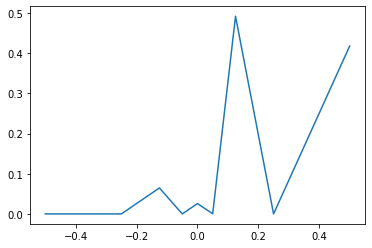

In [7]:
tree = ProbabilityTree(torch.tensor([-0.5,-0.25,-0.125,-0.05,0,0.05,0.125,0.25,0.5]), depth=4, seed=42)
tree.plot_distribution(tree.create_random_distribution())

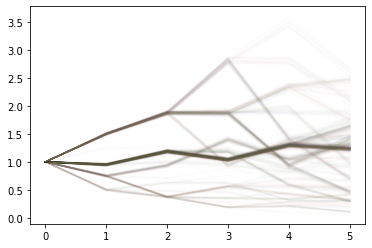

In [8]:

tree = ProbabilityTree(torch.tensor([-0.5,-0.25,-0.125,-0.05,0,0.05,0.125,0.25,0.5]), depth=5, seed=42)
dataset = ProbabilisticDataset(tree, num_samples=999, device=device)

for i in range(len(dataset)):
    sample = dataset[i][2]
    sample = torch.cat([torch.zeros(1, device=device), sample])
    cumprod = torch.cumprod(sample+1, dim=0).cpu().numpy()

    plt.plot(cumprod, alpha=0.01)
batch_size = 333
dl = DataLoader(dataset, batch_size=batch_size, shuffle=True)
plt.show()

In [9]:
def calculate_probability(k, epoch):
    v = k / (k + torch.exp(torch.tensor(epoch / k)))
    return v

def flip(p):
    return random.random() < p

def flip_from_probability(p, batch_size, num_features):
    # Generate random numbers from a uniform distribution [0, 1]
    random_numbers = torch.rand(batch_size)
    # Create a boolean tensor where elements are True if the random number is less than p
    boolean_tensor = random_numbers < p

    boolean_tensor = boolean_tensor.unsqueeze(1).expand(-1, num_features)
    return boolean_tensor
    

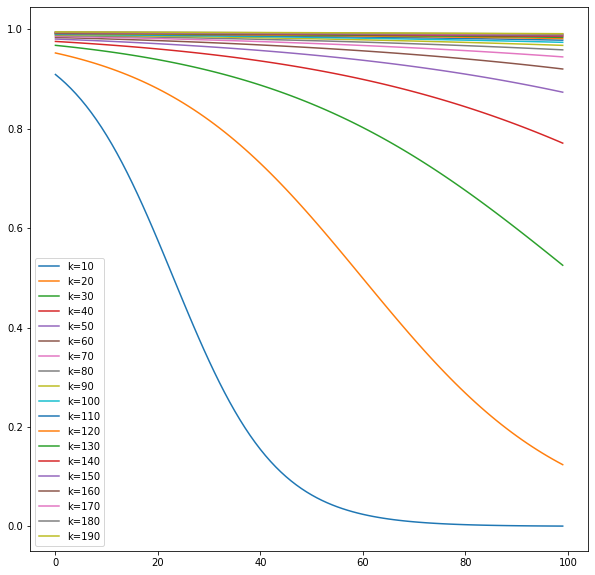

In [10]:
# using matplotlib plot k values from 0.1 -10
plt.figure(figsize=(10,10))
for k in range(10, 200, 10):
    x = []
    y = []
    for epoch in range(100):
        p = calculate_probability(k, epoch)

        x.append(epoch)
        y.append(p)
    plt.plot(x, y, label=f"k={k}")
plt.legend()

        

In [12]:
n_embedd = 128 
model = Transformer(n_Layers=10, n_Embd=n_embedd, max_seq_length=10, n_Classes=len(dataset.discrete_values)).to(device)
best_model = Transformer(n_Layers=10, n_Embd=n_embedd, max_seq_length=10, n_Classes=len(dataset.discrete_values)).to(device)

best_model.load_state_dict(model.state_dict())

# Loss function and optimizer
criterion = BinnedCEPathMSELoss(weight_ce=0.5, weight_mse=0.5).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-6)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.9)

epochs = 1000
k = 100
val_loss = float('inf')
tau = 1
pbar = tqdm(range(epochs))

for epoch in pbar:


    # Training Loop
    model.train()
    p = calculate_probability(k, epoch)
    for batch, discretized_target, true_target in dl:

        optimizer.zero_grad()
        past_key_values = None
        tgt =  discretized_target[:,0].unsqueeze(1)
        singular_predicted = []
        output_predicted = []
        for i in range(0,true_target.shape[1]):

            output, past_key_values = model(batch, tgt, past_key_values)  # Ignoring the last token for target
            if flip(p):
                predicted = discretized_target[:,i+1].unsqueeze(1)
            else:
                predicted = F.gumbel_softmax(logits=output ,tau=tau, hard=True)

            output_predicted.append(output)
            singular_predicted.append(predicted)
            tgt = predicted
        
        output = torch.cat(output_predicted, dim=1)
        singular_predicted = torch.cat(singular_predicted, dim=1)
        singular_predicted = torch.matmul(singular_predicted.float(), dataset.discrete_values.unsqueeze(-1).unsqueeze(0)).squeeze(-1)

        loss = criterion(output, discretized_target[:,1:], singular_predicted, true_target)

        loss.backward()
        optimizer.step()

    # validation loop
    model.eval()
    with torch.no_grad():
        total_loss = 0
        for batch, discretized_target, true_target in dl:

            tgt =  discretized_target[:,0].unsqueeze(1)
            past_key_values = None
            singular_predicted = []
            output_predicted = []
            for i in range(0,true_target.shape[1]):
                
                output, past_key_values = model(batch, tgt, past_key_values)  # Ignoring the last token for target
                predicted = F.gumbel_softmax(logits=output ,tau=tau, hard=True)
                output_predicted.append(output)
                singular_predicted.append(predicted)

                tgt = predicted

            output = torch.cat(output_predicted, dim=1)
            singular_predicted = torch.cat(singular_predicted, dim=1)
            singular_predicted = torch.matmul(singular_predicted.float(), dataset.discrete_values.unsqueeze(-1).unsqueeze(0)).squeeze(-1)
            loss = criterion(output, discretized_target[:,1:], singular_predicted, true_target)
            total_loss += loss.sum().item()

        total_loss = total_loss / len(dl)
        if total_loss < val_loss:
            val_loss = total_loss
            best_model.load_state_dict(model.state_dict())

    # lr_scheduler.step()
    pbar.set_description(desc=f"Epoch: {epoch}, Loss: {total_loss}, Best Loss: {val_loss}, p: {p}")

In [11]:
val_loss

0.36532552043596905

In [12]:
epochs = 10
tau = 10000
all_walks = []
for epoch in tqdm(range(epochs)):
    best_model.eval()

    total_loss = 0    
    # Process each target separately (assuming one input and different targets)
    with torch.no_grad():
        for batch, discretized_target, true_target in dl:
            predicted_walks = []
            # Assuming your model's forward method is designed to take encoder and decoder inputs
            tgt =  discretized_target[:,0].unsqueeze(1)

            for i in range(0,true_target.shape[1]):
                tgt = torch.cat((tgt, predicted), dim=1) if i > 0 else tgt
                output = model(batch, tgt)  # Ignoring the last token for target
                predicted = F.gumbel_softmax(logits=output[:,i] ,tau=tau, hard=True).unsqueeze(1)

            singular_predicted = torch.cat((tgt[:,1:],predicted), dim=1)
            singular_predicted = torch.matmul(singular_predicted.float(), dataset.discrete_values.unsqueeze(-1).unsqueeze(0)).squeeze(-1)
            singular_predicted = torch.cat((torch.zeros(singular_predicted.shape[0], 1).to(device), singular_predicted), dim=1)

            predicted_walks.append(singular_predicted.cpu().numpy())


            # output = best_model(batch, discretized_target[:,:-1])
            # predicted = F.gumbel_softmax(output, tau=tau, hard=True)
            # # Use torch.matmul to get the corresponding discrete values
            # singular_predicted = torch.matmul(predicted.float(), dataset.discrete_values.unsqueeze(-1)).squeeze(-1)
            # singular_predicted = np.array(singular_predicted.cpu().numpy())

            predicted_walks = np.array(predicted_walks).squeeze(0)

            cumprod_pred = np.cumprod(predicted_walks+1, axis=1)
            for i in range(cumprod_pred.shape[0]):
                all_walks.append(cumprod_pred[i])


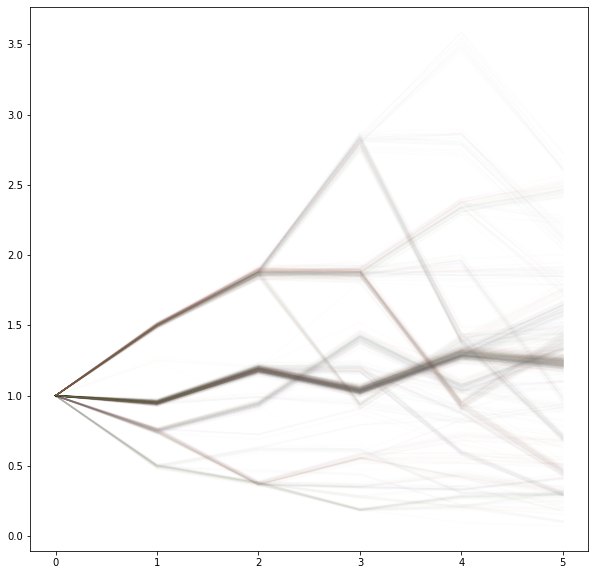

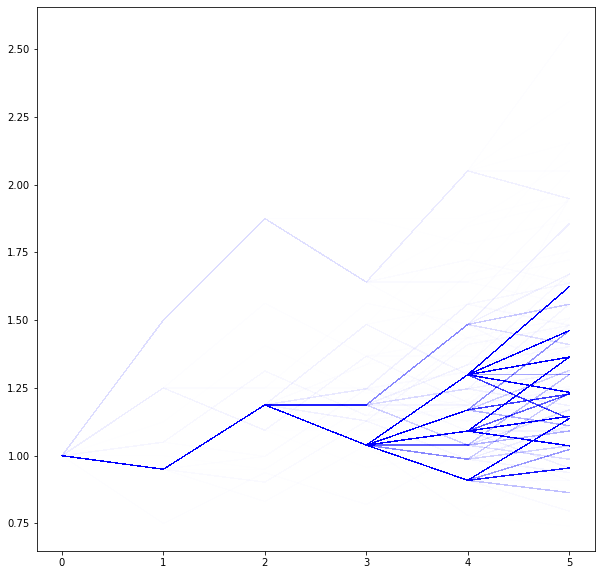

In [18]:
#plot all walks in matplot lib
plt.figure(figsize=(10,10))

for i in range(len(dataset)):
    sample = dataset[i][2]
    sample = torch.cat([torch.zeros(1, device=device), sample])
    cumprod = torch.cumprod(sample+1, dim=0).cpu().numpy()

    plt.plot(cumprod, alpha=0.01)

plt.figure(figsize=(10,10))
for walk in all_walks:
    plt.plot(walk, c='b', alpha=0.005)

plt.show()

In [ ]:
input_1 = dataset[0][0]
tgt_1 = dataset[0][1]

input_2 = dataset[1][0]
tgt_2 = dataset[1][1]

tau = 1

output_1 = best_model(input_1.unsqueeze(0), tgt_1[:-1].unsqueeze(0))
output_2 = best_model(input_1.unsqueeze(0), tgt_2[:-1].unsqueeze(0))
print(tgt_1)
print(tgt_2)
probabilities_1 = F.softmax(output_1, dim=-1)
probabilities_2 = F.softmax(output_2, dim=-1)
print(f'{output_1=}, {output_2=}')
# probabilities_1 = F.gumbel_softmax(logits=output_1 ,tau=tau, hard=False)
# probabilities_2 = F.gumbel_softmax(logits=output_2 ,tau=tau, hard=False)


# Plot probabilities_1
for i, bar in enumerate(probabilities_1.squeeze().detach().cpu().numpy()):
    plt.figure(figsize=(10, 5))  # Create a new figure with desired size
    plt.plot(dataset.discrete_values.detach().cpu().numpy(), bar, color='b', alpha=0.5)
    plt.title(f'Probabilities 1 - Sample {i+1}')
    plt.show()  # Display the figure

# Plot probabilities_2
for i, bar in enumerate(probabilities_2.squeeze().detach().cpu().numpy()):
    plt.figure(figsize=(10, 5))  # Create a new figure with desired size
    plt.plot(dataset.discrete_values.detach().cpu().numpy(), bar, color='r', alpha=0.5)
    plt.title(f'Probabilities 2 - Sample {i+1}')
    plt.show()  # Display the figure

In [ ]:
for i, data in enumerate(dataset):
    input = data[0]
    tgt = data[1]
    output = best_model(input.unsqueeze(0), tgt[:-1].unsqueeze(0))
    probabilities = F.softmax(output, dim=-1)

    current_node = tree.root
    # Plot probabilities
    for j, bar in enumerate(probabilities.squeeze().detach().cpu().numpy()):
        fig, axs = plt.subplots(1, 2, figsize=(20, 5))
        fig.suptitle(f'Probabilities - Sample {i+1} - Target {j+1}')
        axs[0].plot(dataset.discrete_values.detach().cpu().numpy(), bar, color='b', alpha=0.5)
        axs[0].set_title(f'Predicted Probabilities - {i+1} - Sample {j+1}')
        actual_probability = current_node.prob_distribution.cpu().numpy()
        axs[1].plot(dataset.discrete_values.detach().cpu().numpy(), actual_probability, color='r', alpha=0.5)
        axs[1].set_title(f'Actual Probabilities - {i+1} - Sample {j+1}')
        plt.show()
        
        current_node = current_node.children[tgt[j+1].argmax().item()]

    if i == 30:
        break
    

In [2]:
class Transformer(nn.Module):
    def __init__(self, n_Layers, n_Embd=16, max_seq_length=20, n_Classes=1):
        super(Transformer, self).__init__()
        
        self.src_embedding = nn.Linear(in_features=n_Classes, out_features=n_Embd)
        self.tgt_embedding = nn.Linear(in_features=n_Classes, out_features=n_Embd)
        
        self.positional_encoding = nn.Parameter(self.create_positional_encoding(max_seq_length, n_Embd), requires_grad=False)
        
        encoder_layer = nn.TransformerEncoderLayer(n_Embd, nhead=8, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, n_Layers)
        
        decoder_layer = nn.TransformerDecoderLayer(n_Embd, nhead=8, activation="gelu", batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(decoder_layer, n_Layers)
        
        self.lin = nn.Linear(n_Embd, n_Classes)
        
        self.register_buffer("tril", torch.tril(torch.ones(max_seq_length, max_seq_length)))

    @staticmethod
    def create_positional_encoding(max_seq_length, n_Embd):
        pe = torch.zeros(max_seq_length, n_Embd)
        position = torch.arange(0, max_seq_length, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, n_Embd, 2).float() * (-math.log(10000.0) / n_Embd))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)

    def forward(self, src, tgt):
        embedded_src = self.src_embedding(src) + self.positional_encoding[:, :src.size(1), :]
        embedded_tgt = self.tgt_embedding(tgt) + self.positional_encoding[:, :tgt.size(1), :]
        
        memory = self.encoder(embedded_src)
        outs = self.decoder(embedded_tgt, memory, tgt_mask=self.tril[:tgt.size(1), :tgt.size(1)], tgt_is_causal=True)
        return self.lin(outs)



In [11]:
n_embedd = 128 
model = Transformer(n_Layers=10, n_Embd=n_embedd, max_seq_length=10, n_Classes=len(dataset.discrete_values)).to(device)
best_model = Transformer(n_Layers=10, n_Embd=n_embedd, max_seq_length=10, n_Classes=len(dataset.discrete_values)).to(device)

best_model.load_state_dict(model.state_dict())

# Loss function and optimizer
criterion = BinnedCEPathMSELoss(weight_ce=0.5, weight_mse=0.5).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-6)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.9)

epochs = 1000
k = 100
val_loss = float('inf')
tau = 1
pbar = tqdm(range(epochs))
for epoch in pbar:


    # Training Loop
    model.train()
    p = calculate_probability(k, epoch)
    for batch, discretized_target, true_target in dl:
        optimizer.zero_grad()

        tgt =  discretized_target[:,0].unsqueeze(1)
        for i in range(0,true_target.shape[1]):
            tgt = torch.cat((tgt, predicted), dim=1) if i > 0 else tgt
            
            output = model(batch, tgt)  # Ignoring the last token for target
            if flip(p):
                predicted = discretized_target[:,i+1].unsqueeze(1)
            else:
                predicted = F.gumbel_softmax(logits=output[:,i] ,tau=tau, hard=True).unsqueeze(1)
        
        singular_predicted = torch.cat((tgt[:,1:],predicted), dim=1)
        singular_predicted = torch.matmul(singular_predicted.float(), dataset.discrete_values.unsqueeze(-1).unsqueeze(0)).squeeze(-1)

        loss = criterion(output, discretized_target[:,1:], singular_predicted, true_target)

        loss.backward()
        optimizer.step()

    # validation loop
    model.eval()
    with torch.no_grad():
        total_loss = 0
        for batch, discretized_target, true_target in dl:
            tgt =  discretized_target[:,0].unsqueeze(1)

            for i in range(0,true_target.shape[1]):
                tgt = torch.cat((tgt, predicted), dim=1) if i > 0 else tgt
                output = model(batch, tgt)  # Ignoring the last token for target
                predicted = F.gumbel_softmax(logits=output[:,i] ,tau=tau, hard=True).unsqueeze(1)

            singular_predicted = torch.cat((tgt[:,1:],predicted), dim=1)
            singular_predicted = torch.matmul(singular_predicted.float(), dataset.discrete_values.unsqueeze(-1).unsqueeze(0)).squeeze(-1)
            loss = criterion(output, discretized_target[:,1:], singular_predicted, true_target)
            total_loss += loss.sum().item()

        total_loss = total_loss / len(dl)
        if total_loss < val_loss:
            val_loss = total_loss
            best_model.load_state_dict(model.state_dict())

    # lr_scheduler.step()
    pbar.set_description(desc=f"Epoch: {epoch}, Loss: {total_loss}, Best Loss: {val_loss}, p: {p}")

In [58]:
class FeedForwardBaseline(nn.Module):
    def __init__(self):
        super(FeedForwardBaseline, self).__init__()
        self.fc1 = nn.Linear(5*9, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, 5*9)
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        
        x = x.reshape(-1,5*9)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        x = x.reshape(-1,5,9)

        return x

In [50]:
nn_model = FeedForwardBaseline().to(device)
best_nn_model = FeedForwardBaseline().to(device)
optimizer = torch.optim.Adam(nn_model.parameters(), lr=1e-1)
criterion = BinnedCEPathMSELoss(weight_ce=1, weight_mse=1).to(device)
# lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.01)
# criterion = nn.CrossEntropyLoss().to(device)

epochs = 1000
val_loss = 1000
for epoch in range(epochs):
    nn_model.train()

    total_loss = 0    
    # Process each target separately (assuming one input and different targets)

    for batch, discretized_target, true_target in dl:
        output = nn_model(batch)
        predicted = F.gumbel_softmax(output, tau=0.1, hard=True)
        # Use torch.matmul to get the corresponding discrete values
        singular_predicted = torch.matmul(predicted.float(), dataset.discrete_values.unsqueeze(-1))

        # Since the result will have an extra dimension due to unsqueeze, let's remove it
        singular_predicted = singular_predicted.squeeze(-1)

        # Compute loss; you might need to adjust dimensions depending on your setup
        optimizer.zero_grad()
        loss = criterion(output, discretized_target[:,1:], singular_predicted, true_target[:,1:] )
        # loss = criterion(output, discretized_target[:,1:])
        total_loss += loss.item()
        if loss.item() < val_loss:
            val_loss = loss.item()
            best_nn_model.load_state_dict(nn_model.state_dict())
        loss.backward()
        optimizer.step()

    # lr_scheduler.step()

    if epoch % 10 == 0:  # Print average loss every 10 epochs
        print(f'Epoch {epoch}, Loss: {total_loss}')

Epoch 0, Loss: 1.6498539447784424
Epoch 10, Loss: 1.2612816095352173
Epoch 20, Loss: 3.2981181144714355
Epoch 30, Loss: 1.3121421337127686
Epoch 40, Loss: 0.7589055299758911
Epoch 50, Loss: 1.0593223571777344
Epoch 60, Loss: 0.7469817996025085
Epoch 70, Loss: 0.8069965839385986
Epoch 80, Loss: 0.7923926711082458
Epoch 90, Loss: 0.6705412864685059
Epoch 100, Loss: 0.7995102405548096
Epoch 110, Loss: 4.046611785888672
Epoch 120, Loss: 1.1116923093795776
Epoch 130, Loss: 0.8754215240478516
Epoch 140, Loss: 0.6599616408348083
Epoch 150, Loss: 0.7406923770904541
Epoch 160, Loss: 1.0862866640090942
Epoch 170, Loss: 1.2587640285491943
Epoch 180, Loss: 0.7517479658126831
Epoch 190, Loss: 0.8147278428077698
Epoch 200, Loss: 0.4158152937889099
Epoch 210, Loss: 0.5555380582809448
Epoch 220, Loss: 0.552475094795227
Epoch 230, Loss: 0.42958179116249084
Epoch 240, Loss: 0.6243321895599365
Epoch 250, Loss: 0.6179507374763489
Epoch 260, Loss: 0.47226715087890625
Epoch 270, Loss: 0.5977551937103271
Epo

In [237]:
val_loss

0.45759832859039307

In [238]:
epochs = 10
all_walks = []
for epoch in range(epochs):
    best_nn_model.eval()
    total_loss = 0    

    for batch, discretized_target, true_target in dl:
        output = best_nn_model(batch)
        probabilities = F.gumbel_softmax(output, tau=0.1, hard=False)
        # Create a Categorical distribution from the probabilities
        distribution = Categorical(probs=probabilities)
        # Sample from the distribution
        samples = distribution.sample()
        singular_predicted = dataset.discrete_values[samples]
        singular_predicted = np.array(singular_predicted.cpu())
        cumprod_pred = np.cumprod(singular_predicted+1, axis=1)
        all_walks.append(cumprod_pred[0])
        all_walks.append(cumprod_pred[1])
        print(len(all_walks))


2
4
6
8
10
12
14
16
18
20


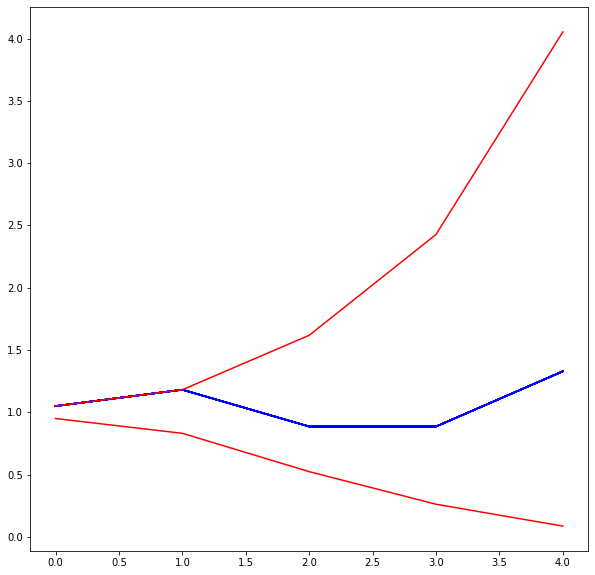

In [239]:
#plot all walks in matplot lib
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
for walk in all_walks:
    plt.plot(walk, c='b')


plt.plot(np.cumprod(target_1[1:]+1), c='r')
plt.plot(np.cumprod(target_2[1:]+1), c='r')
# plt.plot(np.cumprod(encoder_input+1), c='r')
plt.show()

tensor([[0.0000e+00, 0.0000e+00, 1.0434e-40, 5.3240e-32, 1.2664e-38, 1.0000e+00,
         3.2526e-28, 1.8102e-31, 3.1059e-23],
        [2.0834e-32, 3.7994e-30, 1.1245e-17, 0.0000e+00, 2.4511e-29, 1.5278e-31,
         1.0000e+00, 1.0596e-38, 4.4989e-36],
        [8.4078e-45, 1.0000e+00, 7.5540e-41, 0.0000e+00, 2.6099e-30, 4.3440e-44,
         2.8026e-45, 2.8401e-40, 9.8091e-43],
        [1.1597e-24, 0.0000e+00, 8.9632e-27, 0.0000e+00, 1.0000e+00, 9.8074e-30,
         1.4658e-30, 2.4701e-32, 1.6765e-18],
        [1.3835e-06, 3.3331e-32, 8.1746e-22, 2.0755e-33, 1.6759e-06, 1.0300e-10,
         4.7981e-05, 1.5291e-14, 9.9995e-01]], grad_fn=<ToCopyBackward0>)


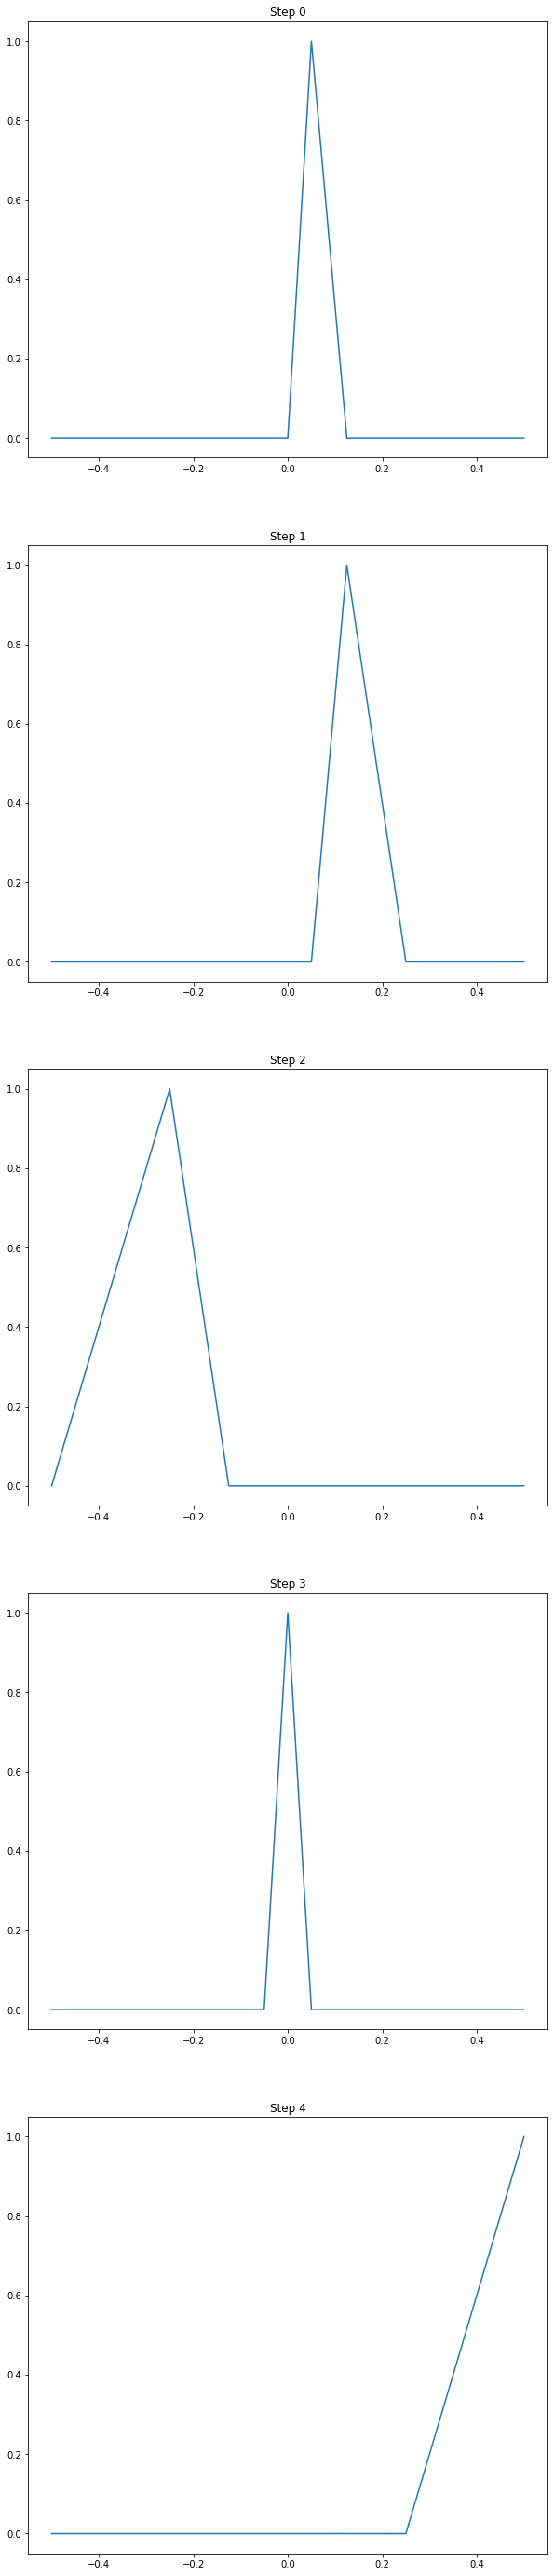

In [240]:
input = dataset[0][0]
tgt = dataset[0][1]

output = best_nn_model(dataset[0][0].unsqueeze(0))
distribution = Categorical(logits=output)

probs = distribution.probs.squeeze(0).to("cpu")
print(probs)

fig, axs = plt.subplots(len(probs), figsize=(10,50))
for idx, prob_dist in enumerate(probs):
    axs[idx].plot(dataset.discrete_values.to("cpu"), prob_dist.detach().numpy())
    axs[idx].set_title(f"Step {idx}")

plt.show()